## 股票

使用特徵: ['sma60', 'sma240', 'adx', 'kama', 'breakout_20', 'breakout_240', 'trust_in_5', 'r2_60', 'yoy', 'yoy_ma3_bias', 'amount60', 'amount20', 'sma20', 'r2_20', 't_f_sync']
使用特徵數量: 15
訓練集: (31503, 38)
驗證集: (8792, 38)
開始訓練 (Shooting High Mode)...
0:	test: 0.3457792	best: 0.3457792 (0)	total: 223ms	remaining: 9m 16s
100:	test: 0.5965005	best: 0.6146388 (83)	total: 3.99s	remaining: 1m 34s
200:	test: 0.5808489	best: 0.6146388 (83)	total: 7.69s	remaining: 1m 28s
300:	test: 0.5752458	best: 0.6146388 (83)	total: 11.4s	remaining: 1m 22s
400:	test: 0.6206031	best: 0.6206031 (400)	total: 15s	remaining: 1m 18s
500:	test: 0.6084027	best: 0.6206031 (400)	total: 18.7s	remaining: 1m 14s
600:	test: 0.5954975	best: 0.6219031 (520)	total: 23s	remaining: 1m 12s
700:	test: 0.6285771	best: 0.6297261 (696)	total: 27.4s	remaining: 1m 10s
800:	test: 0.6269482	best: 0.6325230 (701)	total: 31s	remaining: 1m 5s
900:	test: 0.6270524	best: 0.6337780 (822)	total: 35.3s	remaining: 1m 2s
1000:	test: 0.6310770	best: 0.

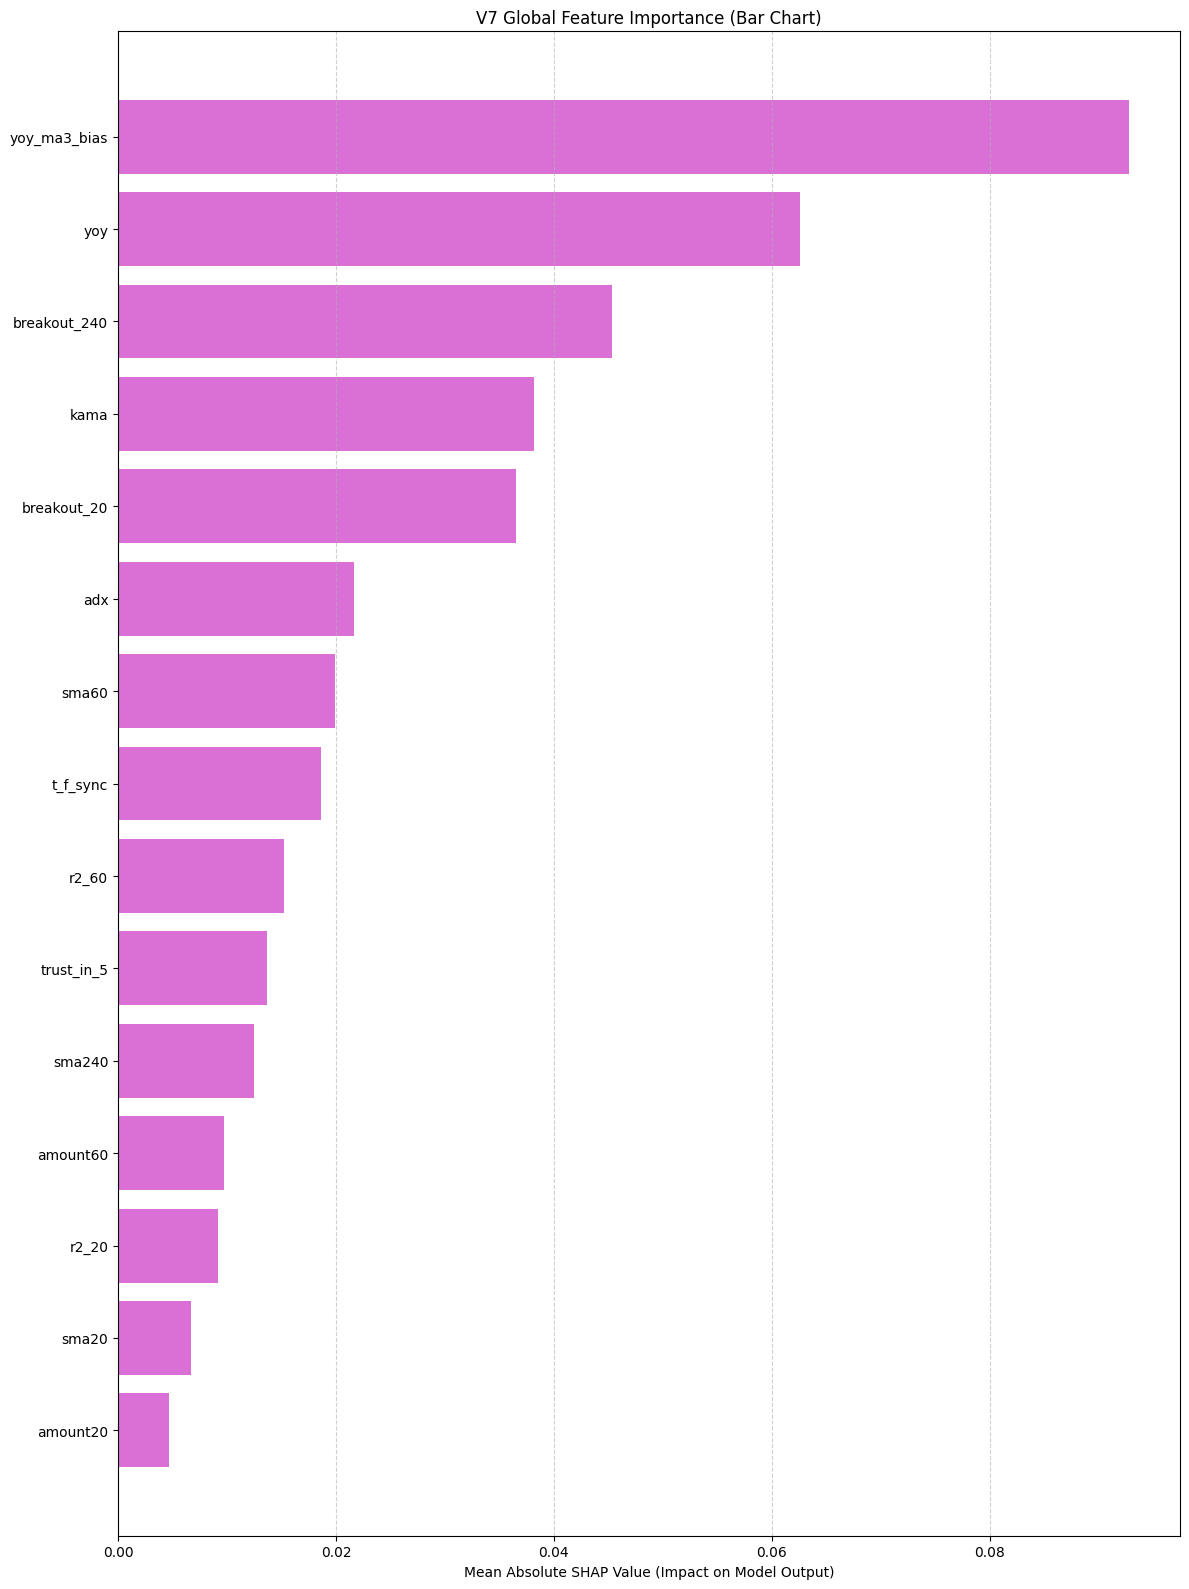

繪製 SHAP Summary Plot (蜂群圖)...


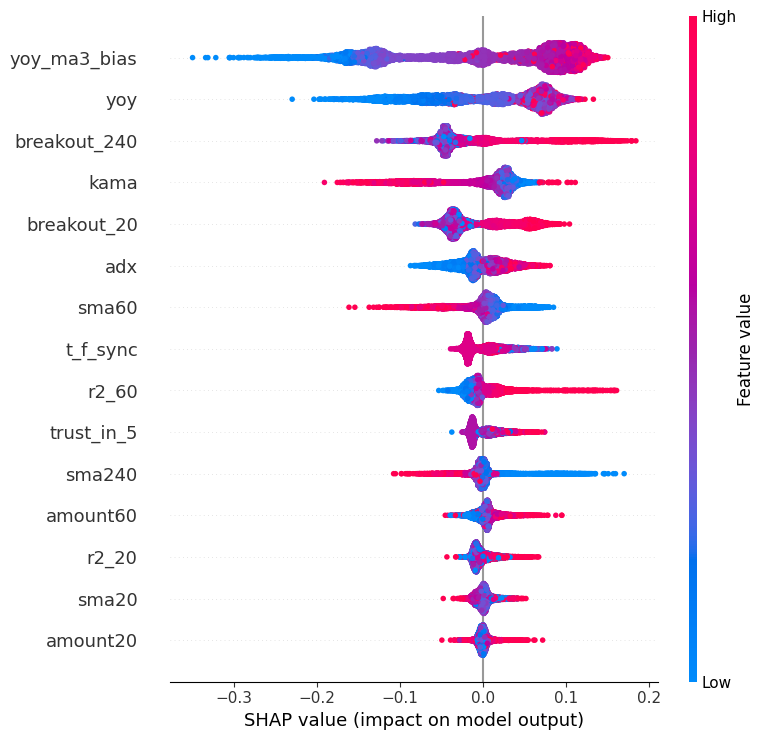

--- SHAP 重要性清單 (由高到低) ---
yoy_ma3_bias: 0.0928
yoy: 0.0626
breakout_240: 0.0454
kama: 0.0382
breakout_20: 0.0365
adx: 0.0217
sma60: 0.0199
t_f_sync: 0.0186
r2_60: 0.0152
trust_in_5: 0.0137
sma240: 0.0125
amount60: 0.0097
r2_20: 0.0092
sma20: 0.0067
amount20: 0.0046


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from catboost import Pool, CatBoostRanker
import shap  # 新增引用

%matplotlib inline
import matplotlib.pyplot as plt

# 假設妳的 ipynb 存在專案根目錄，data 在子目錄
df = pd.read_csv(r'c:\Users\Lynn610\Documents\kitsune_stock_system\data\features\train_v16.csv') 
df['date'] = pd.to_datetime(df['date'])

# 資料準備
df = df.sort_values(['date', 'id']).reset_index(drop=True)

col =[ col for col in df.columns]

# --- 1. 資料準備與設定 ---
# 
# #v-8

# X_col = [
# 'sma60', 'sma240','sma10',
# 'adx',  'kama','atr', 
# 'macd_hist',
# 'amount60', 
# 'breakout_20', 'breakout_60', 
# 'trust_in_3',
# 'r2_60',
# 'bb_width',
# 'mom','yoy','yoy_ma3_bias',
# #不要的
# #'sma5',#'sma20',#'yoy_ma6',#'mom_ma3','mom_ma6''yoy_ma3'#'r2_10','r2_5','r2_20','foreign_in_5', #'foreign_in_10', 'foreign_in_20', 'foreign_in_3',
# #'av_price(vwap)', #'trust_in_5', #'trust_in_10',#'amount10','amount20',#'macd_signal', 'macd',#'sma5',#'sma20',#'cci','rsi',
# ]


# v-9

X_col = ["sma60", "sma240",  "adx", "kama","breakout_20", "breakout_240", 
                    "trust_in_5","r2_60", "yoy", "yoy_ma3_bias",
					"amount60",
                    'amount20',"sma20","r2_20","t_f_sync",#'atr',"mom",
					]

y_col = 'label'
group_col = 'date'

print(f"使用特徵: {X_col}")
print(f"使用特徵數量: {len(X_col)}")

# 時間序列切分
dates = df['date'].unique()
split_idx = int(len(dates) * 0.8)
split_date = dates[split_idx]

train_df = df[df['date'] < split_date]
test_df = df[df['date'] >= split_date]

print(f"訓練集: {train_df.shape}")
print(f"驗證集: {test_df.shape}")

# 建立 Pool
train_pool = Pool(
    data=train_df[X_col],
    label=train_df[y_col],
    group_id=train_df[group_col].astype('category').cat.codes
)

test_pool = Pool(
    data=test_df[X_col],
    label=test_df[y_col],
    group_id=test_df[group_col].astype('category').cat.codes
)

# --- 2. 訓練模型 ---
model = CatBoostRanker(
    iterations=2500,
    learning_rate=0.005,
    depth=6,
    loss_function='YetiRank',
    eval_metric='NDCG:top=5',
    custom_metric=['PrecisionAt:top=5'],
    verbose=100,
    random_seed=42,
    early_stopping_rounds=600,
    #feature_weights = {"trust_in_5": 1.2}
)

print("開始訓練 (Shooting High Mode)...")
model.fit(train_pool, eval_set=test_pool, plot=False)

# --- 3. SHAP 計算 ---
shap_results = model.get_feature_importance(data=test_pool, type='ShapValues')

# 移除最後一欄 (Base Value)，保留特徵貢獻值
shap_values = shap_results[:, :-1]

# 計算平均絕對重要性 (給長條圖用)
shap_importance = np.abs(shap_values).mean(axis=0)
sorted_idx = shap_importance.argsort()

# --- 4. 繪圖 A: 傳統特徵重要性 (長條圖) ---
plt.figure(figsize=(12, 16))
plt.barh(range(len(sorted_idx)), shap_importance[sorted_idx], color='orchid', align='center')
plt.yticks(range(len(sorted_idx)), [X_col[i] for i in sorted_idx])
plt.xlabel('Mean Absolute SHAP Value (Impact on Model Output)')
plt.title('V7 Global Feature Importance (Bar Chart)')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- 5. 繪圖 B: SHAP Summary Plot (蜂群圖) --- [新增部分]
print("繪製 SHAP Summary Plot (蜂群圖)...")
plt.figure() 
# shap_values: 每個樣本的 SHAP 值
# test_df[X_col]: 原始特徵數值 (用於決定點的顏色，紅高藍低)
shap.summary_plot(shap_values, test_df[X_col], show=True)

# --- 6. 印出清單 ---
print("--- SHAP 重要性清單 (由高到低) ---")
for i in sorted_idx[::-1]:
    print(f"{X_col[i]}: {shap_importance[i]:.4f}")